# X-ray surface brightness with the 3D emissivity table

This notebook shows how to use the 3D X-ray emissivity table
`data/etable_05_2keV_3D.hdf5` with `cgm_toolkit.cgm_profiles`.

The table holds the CIE emissivity $\Lambda(T, z, Z)$ in the **observer-frame** 0.5–2 keV band, in erg s$^{-1}$ cm$^{3}$, tabulated over

| axis | range | bins |
|---|---|---|
| temperature $T$ | 0.001 – 20 keV | 101, log-spaced |
| redshift $z$ | 0 – 4 | 51, log-spaced in $1+z$ |
| metallicity $Z$ | 0.001 – 10 $Z_\odot$ | 21, log-spaced |

It has no Galactic absorption and no instrument response. To rebuild it, or to make a table for another band, absorbing column or instrument, run

```bash
python scripts/make_etable_3D.py --help
```

(this needs `pyatomdb` with the AtomDB data installed).

**Why redshift is an axis.** The band is fixed in the observer frame, so a source at redshift $z$ is seen through the rest-frame band $[0.5, 2](1+z)$ keV. Each photon is also weighted by its *observed* energy, so one factor of $1/(1+z)$ is already in $\Lambda$. The surface brightness therefore only needs the remaining $(1+z)^3$:

$$S_X(R) = \frac{1}{4\pi (1+z)^3} \int n_e\, n_H\, \Lambda(T, z, Z)\, dl .$$

`HaloProfile` does this for you.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from cgm_toolkit import cgm_profiles
from cgm_toolkit.xray_emissivity import XrayEmissivity

etable_file = cgm_profiles.etable_file_path  # data/etable_05_2keV_3D.hdf5

## 1. Look at the table

`read_emissivity_table` loads the table and its axes. Redshift bins are stored as $1+z$.

In [2]:
xray = XrayEmissivity()
xray.read_emissivity_table(etable_file)

print("table shape [T, z, Z]:", xray.etable.shape)
print(f"band:        {xray.emin:.2f} - {xray.emax:.2f} keV")
print(f"temperature: {xray.tbins[0]:.3g} - {xray.tbins[-1]:.3g} keV")
print(f"redshift:    {xray.rbins[0] - 1:.3g} - {xray.rbins[-1] - 1:.3g}")
print(f"metallicity: {xray.mbins[0]:.3g} - {xray.mbins[-1]:.3g} Zsun")

table shape [T, z, Z]: (101, 51, 21)
band:        0.50 - 2.00 keV
temperature: 0.001 - 20 keV
redshift:    0 - 4
metallicity: 0.001 - 10 Zsun


`return_interpolated_emissivity(temperature, redshift, metallicity)` interpolates the table (linearly in log space). Inputs broadcast against each other, so you can pass an array of temperatures with a scalar redshift and metallicity. Values outside the table are clamped to its edges.

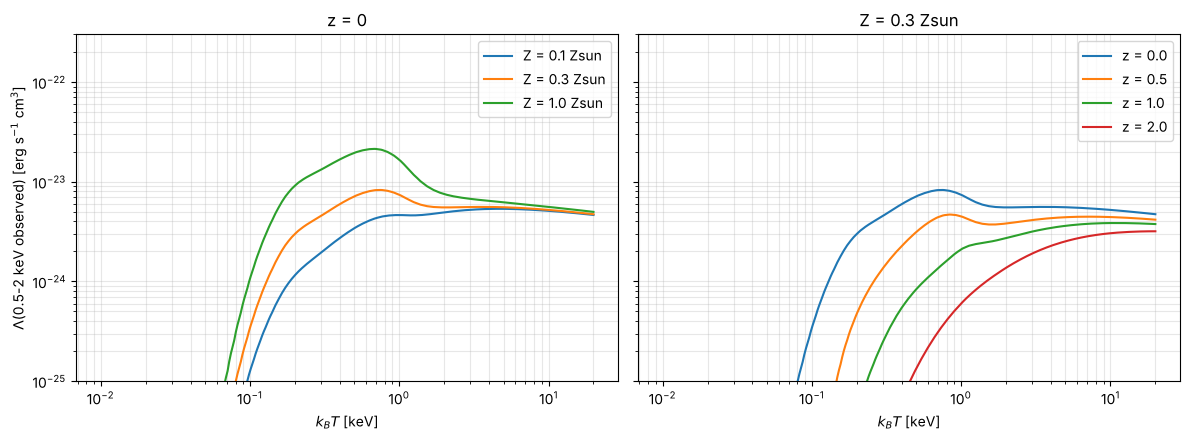

In [3]:
T = np.logspace(-2, np.log10(20), 300)  # keV

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for Zm in [0.1, 0.3, 1.0]:
    axes[0].loglog(T, xray.return_interpolated_emissivity(T, 0.0, Zm), label=f"Z = {Zm} Zsun")
axes[0].set_title("z = 0")

for z in [0.0, 0.5, 1.0, 2.0]:
    axes[1].loglog(T, xray.return_interpolated_emissivity(T, z, 0.3), label=f"z = {z}")
axes[1].set_title("Z = 0.3 Zsun")

for ax in axes:
    ax.set_xlabel(r"$k_B T$ [keV]")
    ax.set_ylim(1e-25, 3e-22)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
axes[0].set_ylabel(r"$\Lambda$(0.5-2 keV observed) [erg s$^{-1}$ cm$^3$]")
plt.tight_layout()
plt.show()

Higher redshift moves the observed band to harder rest-frame energies, so cool gas fades and hot gas brightens relative to $z=0$. The emissivity also drops overall by roughly $1/(1+z)$ from the observed photon energy.

## 2. A model halo

Same toy profiles as `example_xsb_profile.ipynb`: a $\beta$-model density, a temperature that falls from $2\times10^6$ K to $8\times10^5$ K, and a metallicity falling from 0.5 to 0.1 $Z_\odot$.

`HaloProfile` expects:
- `radial_bin` in kpc
- `pressure`: electron pressure in keV cm$^{-3}$
- `density`: electron number density in cm$^{-3}$
- `metallicity` in $Z_\odot$
- `temperature` in keV (optional; otherwise $T = P_e / n_e$)

In [4]:
k_B = 1.380649e-16           # erg/K
keV_to_erg = 1.602176634e-9  # erg/keV
Mpc_to_cm = 3.0856e24

r_kpc = np.logspace(1, 3, 500)  # 10 - 1000 kpc

n_e = 1e-3 * (1.0 + (r_kpc / 10.0) ** 2) ** (-1.5 * 0.5)                # cm^-3
T_K = 8.0e5 + (2.0e6 - 8.0e5) / (1.0 + (r_kpc / 100.0) ** 2)            # K
T_keV = k_B * T_K / keV_to_erg
Z = 0.1 + (0.5 - 0.1) / (1.0 + (r_kpc / 50.0) ** 1.5)                   # Zsun
P_e = n_e * T_keV                                                       # keV cm^-3

## 3. Emissivity and surface brightness profiles

`spherical_xray_emissivity_profile` returns $n_e n_H \Lambda / [4\pi(1+z)^3]$ in erg s$^{-1}$ cm$^{-3}$ sr$^{-1}$, using the halo's own redshift to look up $\Lambda$. `projected_xray_surface_brightness_profile` integrates it along the line of sight to give $S_X$ in erg s$^{-1}$ cm$^{-2}$ sr$^{-1}$. Both default to `data/etable_05_2keV_3D.hdf5`; pass `etable=...` to use another 3D table.

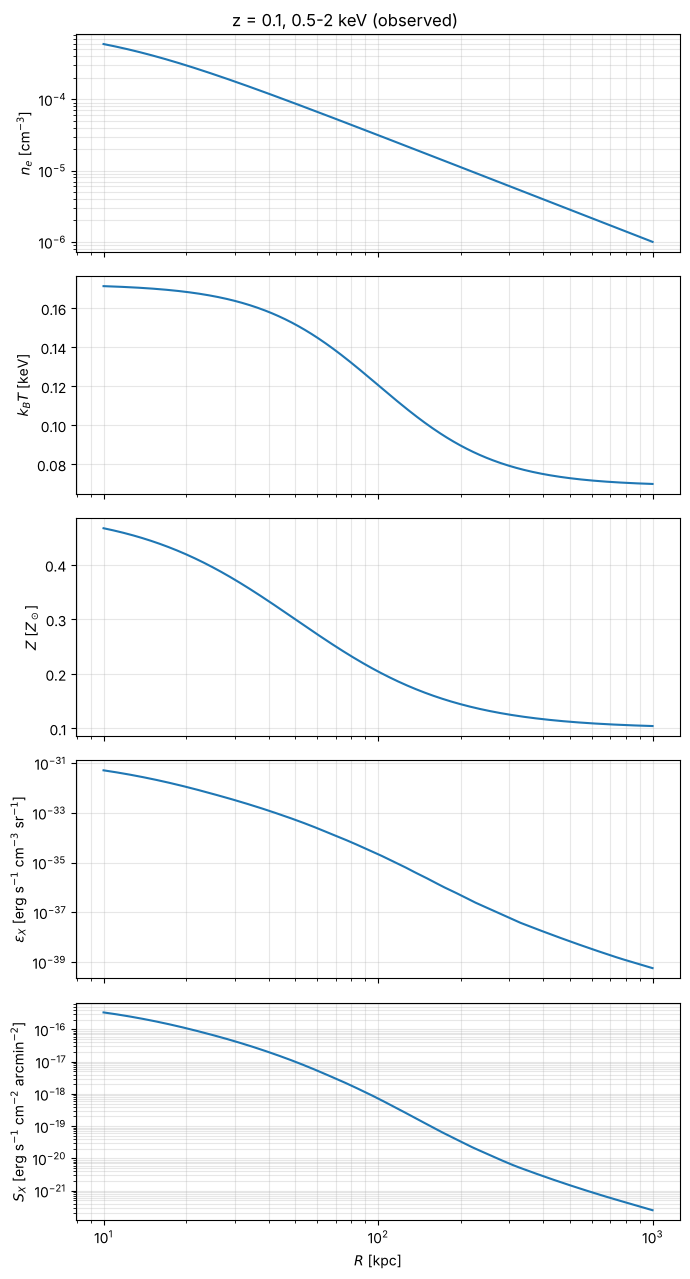

In [5]:
redshift = 0.1
halo = cgm_profiles.HaloProfile(redshift, r_kpc, P_e, n_e, Z, temperature=T_keV)

eps_X = halo.spherical_xray_emissivity_profile(r_kpc)          # erg/s/cm^3/sr
S_X = halo.projected_xray_surface_brightness_profile(r_kpc)     # erg/s/cm^2/sr

sr_to_arcmin2 = (180.0 / np.pi * 60.0) ** 2
S_X_arcmin2 = S_X / sr_to_arcmin2                               # erg/s/cm^2/arcmin^2

fig, axes = plt.subplots(5, 1, figsize=(7, 13), sharex=True)
axes[0].loglog(r_kpc, n_e);         axes[0].set_ylabel(r"$n_e$ [cm$^{-3}$]")
axes[1].semilogx(r_kpc, T_keV);     axes[1].set_ylabel(r"$k_B T$ [keV]")
axes[2].semilogx(r_kpc, Z);         axes[2].set_ylabel(r"$Z$ [$Z_\odot$]")
axes[3].loglog(r_kpc, eps_X);       axes[3].set_ylabel(r"$\epsilon_X$ [erg s$^{-1}$ cm$^{-3}$ sr$^{-1}$]")
axes[4].loglog(r_kpc, S_X_arcmin2); axes[4].set_ylabel(r"$S_X$ [erg s$^{-1}$ cm$^{-2}$ arcmin$^{-2}$]")
axes[4].set_xlabel(r"$R$ [kpc]")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
fig.suptitle(f"z = {redshift}, 0.5-2 keV (observed)")
plt.tight_layout()
plt.show()

## 4. The same halo at different redshifts

Here we place the identical halo at several redshifts. The drop in $S_X$ combines the $(1+z)^3$ dimming with the change in $\Lambda$ as the observed band samples harder rest-frame energies. The bottom panel divides out the $(1+z)^3$ so only the change in $\Lambda$ is left. This halo is cool (0.07–0.17 keV), where $\Lambda$ falls steeply as the band shifts to harder rest-frame energies (see section 1), so the effect is large; for keV gas it is much milder.

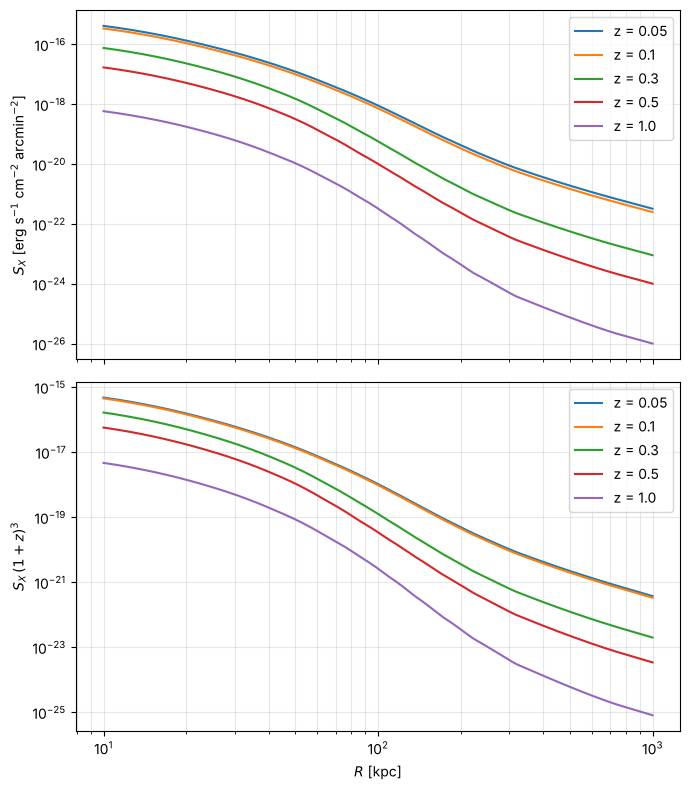

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(7, 8), sharex=True)

redshifts = [0.05, 0.1, 0.3, 0.5, 1.0]
for z in redshifts:
    h = cgm_profiles.HaloProfile(z, r_kpc, P_e, n_e, Z, temperature=T_keV)
    sx = h.projected_xray_surface_brightness_profile(r_kpc) / sr_to_arcmin2
    axes[0].loglog(r_kpc, sx, label=f"z = {z}")
    axes[1].loglog(r_kpc, sx * (1.0 + z) ** 3, label=f"z = {z}")

axes[0].set_ylabel(r"$S_X$ [erg s$^{-1}$ cm$^{-2}$ arcmin$^{-2}$]")
axes[1].set_ylabel(r"$S_X\,(1+z)^3$")
axes[1].set_xlabel(r"$R$ [kpc]")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Using other tables

Older 2D tables in `data/` (`etable.hdf5`, `etable_05_2keV.hdf5`, `etable_05_2keV_cnts.hdf5`, `etable_erosita_cnts.hdf5`) and tables made with `scripts/make_etable_2D.py` have no redshift axis. They still work: they are treated as $z=0$ tables and the same emissivity is used at every redshift, with a warning when $z>0$. That leaves out the band shift and, for erg tables, the $1/(1+z)$ photon-energy factor, so for $z>0$ it is better to regenerate them as 3D tables with `scripts/make_etable_3D.py`. For example, a photon-count table through an instrument response with Galactic absorption:

```bash
python scripts/make_etable_3D.py -o data/etable_cnts_3D.hdf5 --photons --nH 2e20 \
    --rmf responses/rmf01_sdtq.fits --arf responses/arf01_200nmAl_sdtq.fits
```

and then

```python
S_X = halo.projected_xray_surface_brightness_profile(r_kpc, etable="../data/etable_cnts_3D.hdf5")
```

With an ARF the table includes the effective area, so $S_X$ comes out in counts s$^{-1}$ sr$^{-1}$ instead of per cm$^{2}$.